<a href="https://colab.research.google.com/github/tikakukeko/Studi_Kasus_Dan_Implementasi_Kode_Atikah_Putri_Utami_G1A024027/blob/main/Studi_Kasus_Introduction_to_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studi Kasus Lengkap: Introduction to Machine Learning
### Informatics Practitioner Lecture Series 2026



## 1. Latar Belakang

Machine Learning (ML) merupakan bagian dari Artificial Intelligence (AI) yang memungkinkan komputer mempelajari pola dari data untuk menghasilkan prediksi atau keputusan. Pada studi kasus ini, ML digunakan untuk memperkirakan apakah seorang mahasiswa akan lulus berdasarkan beberapa indikator belajar, seperti waktu belajar, persentase kehadiran, dan nilai tugas.

Contoh ini termasuk **Supervised Learning**, karena dataset memiliki target/label yang telah diketahui, yaitu status lulus atau tidak lulus. Karena target berupa kategori, tugas ini merupakan **klasifikasi**.

## 2. Rumusan Masalah

1. Bagaimana karakteristik data belajar mahasiswa pada dataset simulasi?
2. Dapatkah model klasifikasi mempelajari pola dari fitur belajar yang tersedia?
3. Bagaimana kinerja model ketika diuji menggunakan data yang tidak dipakai saat pelatihan?
4. Apa batasan dan pertimbangan etika yang perlu diperhatikan sebelum ML digunakan pada situasi nyata?

## 3. Tujuan

- Memahami alur kerja dasar Machine Learning.
- Mengenali perbedaan fitur dan target.
- Melakukan eksplorasi dan prapemrosesan data.
- Membagi data menjadi training dan testing.
- Melatih model klasifikasi sederhana.
- Mengevaluasi model menggunakan accuracy, precision, recall, F1-score, dan confusion matrix.
- Menjelaskan mengapa hasil model harus ditafsirkan secara kritis dan bertanggung jawab.

## 4. Konsep Utama

- **Artificial Intelligence (AI):** bidang yang mencakup sistem yang melakukan tugas yang biasanya membutuhkan kecerdasan manusia.
- **Machine Learning (ML):** pendekatan yang mempelajari pola dari data.
- **Deep Learning:** bagian dari ML yang menggunakan jaringan saraf tiruan berlapis untuk mempelajari pola kompleks.
- **Fitur (features):** kolom masukan yang digunakan model untuk membuat prediksi.
- **Target/label:** nilai yang ingin diprediksi.
- **Training data:** data untuk melatih model.
- **Testing data:** data terpisah untuk mengevaluasi model.
- **Overfitting:** kondisi saat model terlalu menyesuaikan diri dengan data pelatihan dan kurang baik pada data baru.

## 5. Jenis-Jenis Machine Learning

| Jenis | Karakteristik | Contoh |
|---|---|---|
| Supervised Learning | Data memiliki label/target | Prediksi kelulusan, deteksi spam |
| Unsupervised Learning | Data tidak memiliki label target | Segmentasi pelanggan dengan K-Means |
| Semi-Supervised Learning | Menggabungkan sedikit data berlabel dan banyak data tanpa label | Klasifikasi gambar saat label terbatas |
| Reinforcement Learning | Agen belajar melalui interaksi, reward, dan penalty | Agen permainan atau robotika |

Studi kasus notebook ini menggunakan **Supervised Learning** karena status kelulusan tersedia sebagai label pada data simulasi.

## 6. Studi Kasus dan Definisi Variabel

Dataset simulasi memuat indikator belajar berikut:

- `jam_belajar`: rata-rata jam belajar per hari.
- `kehadiran_pct`: persentase kehadiran.
- `nilai_tugas`: nilai tugas pada skala 0–100.
- `lulus`: target klasifikasi; 1 berarti lulus dan 0 berarti tidak lulus.

Label pada data simulasi dibuat berdasarkan kombinasi indikator dan sedikit variasi acak. Karena label dibentuk dengan aturan buatan, model hanya mendemonstrasikan cara kerja klasifikasi dan tidak membuktikan faktor penyebab kelulusan di dunia nyata.

## 7. Menyiapkan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 8. Membuat Dataset Simulasi

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 500

jam_belajar = rng.uniform(0.5, 6.0, n)
kehadiran_pct = rng.uniform(50, 100, n)
nilai_tugas = rng.uniform(35, 100, n)

# Skor buatan hanya untuk membangun contoh pembelajaran.
skor = (
    0.30 * (jam_belajar / 6 * 100)
    + 0.35 * kehadiran_pct
    + 0.35 * nilai_tugas
    + rng.normal(0, 8, n)
)
lulus = (skor >= 65).astype(int)

df = pd.DataFrame({
    "jam_belajar": jam_belajar.round(2),
    "kehadiran_pct": kehadiran_pct.round(2),
    "nilai_tugas": nilai_tugas.round(2),
    "lulus": lulus
})

df.head()

,jam_belajar,kehadiran_pct,nilai_tugas,lulus
0,4.76,86.84,39.03,1
1,2.91,94.32,64.79,0
2,5.22,96.05,43.39,1
3,4.34,75.18,44.90,1
4,1.02,76.01,76.10,1


## 9. Memahami Data (Data Understanding)



In [3]:
print("Ukuran dataset:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nNilai kosong per kolom:")
print(df.isna().sum())
print("\nStatistik ringkas:")
display(df.describe())
print("\nDistribusi target (0 = tidak lulus, 1 = lulus):")
print(df["lulus"].value_counts())

Ukuran dataset: (500, 4)

Tipe data:
jam_belajar      float64
kehadiran_pct    float64
nilai_tugas      float64
lulus              int64
dtype: object

Nilai kosong per kolom:
jam_belajar      0
kehadiran_pct    0
nilai_tugas      0
lulus            0
dtype: int64

Statistik ringkas:


,jam_belajar,kehadiran_pct,nilai_tugas,lulus
count,500.000000,500.000000,500.000000,500.000000
mean,3.226300,74.933820,67.797260,0.486000
std,1.577105,14.830178,18.948788,0.500305
min,0.530000,50.060000,35.030000,0.000000
25%,1.797500,62.165000,50.990000,0.000000
50%,3.255000,74.685000,67.010000,0.000000
75%,4.612500,88.172500,84.337500,1.000000
max,6.000000,99.940000,99.960000,1.000000



Distribusi target (0 = tidak lulus, 1 = lulus):
lulus
0    257
1    243
Name: count, dtype: int64


### Visualisasi distribusi target

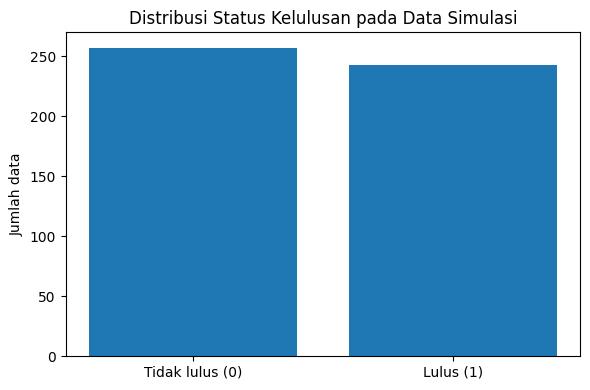

In [4]:
counts = df["lulus"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Tidak lulus (0)", "Lulus (1)"], counts.values)
plt.title("Distribusi Status Kelulusan pada Data Simulasi")
plt.ylabel("Jumlah data")
plt.tight_layout()
plt.show()

**Interpretasi:** perhatikan apakah jumlah data pada kedua kelas relatif seimbang. Jika satu kelas jauh lebih dominan, accuracy saja bisa memberikan gambaran yang menyesatkan. Dalam praktik nyata, distribusi target harus diperiksa sebelum menentukan metrik utama.

## 10. Menyiapkan Fitur dan Target



In [5]:
X = df[["jam_belajar", "kehadiran_pct", "nilai_tugas"]]
y = df["lulus"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

Jumlah data training: 400
Jumlah data testing : 100


## 11. Melatih Model



In [6]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
print("Pelatihan model selesai.")

Pelatihan model selesai.


## 12. Evaluasi Model



In [7]:
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}
pd.DataFrame([metrics]).round(3)

,Accuracy,Precision,Recall,F1-score
0,0.84,0.824,0.857,0.84


### Classification report dan confusion matrix

              precision    recall  f1-score   support

 Tidak lulus       0.86      0.82      0.84        51
       Lulus       0.82      0.86      0.84        49

    accuracy                           0.84       100
   macro avg       0.84      0.84      0.84       100
weighted avg       0.84      0.84      0.84       100



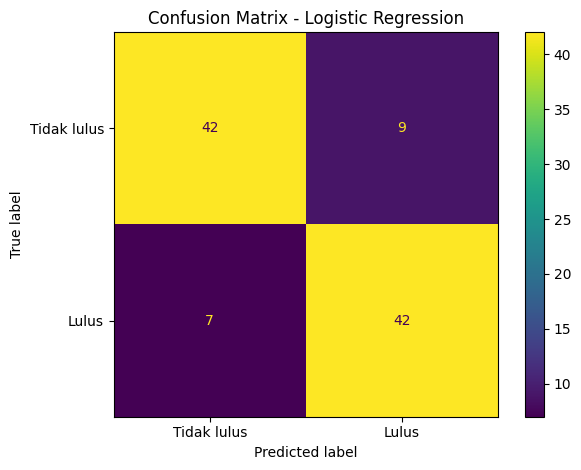

In [8]:
print(classification_report(
    y_test, y_pred,
    target_names=["Tidak lulus", "Lulus"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Tidak lulus", "Lulus"],
    values_format="d"
)
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

## 13. Mencoba Prediksi Data Baru



In [9]:
mahasiswa_baru = pd.DataFrame([{
    "jam_belajar": 3.5,
    "kehadiran_pct": 88,
    "nilai_tugas": 78
}])

prediksi = model.predict(mahasiswa_baru)[0]
probabilitas = model.predict_proba(mahasiswa_baru)[0]

print("Prediksi kelas:", "Lulus" if prediksi == 1 else "Tidak lulus")
print("Probabilitas kelas tidak lulus:", round(probabilitas[0], 3))
print("Probabilitas kelas lulus      :", round(probabilitas[1], 3))

Prediksi kelas: Lulus
Probabilitas kelas tidak lulus: 0.098
Probabilitas kelas lulus      : 0.902


## 14. Alur Kerja Machine Learning

1. **Pengumpulan data:** mengumpulkan data yang relevan dan sah digunakan.
2. **Pembersihan data:** menangani nilai kosong, duplikasi, dan kesalahan format.
3. **Eksplorasi data:** memahami distribusi dan hubungan antarvariabel.
4. **Pemilihan fitur:** memilih informasi yang relevan untuk prediksi.
5. **Pembagian data:** memisahkan training dan testing.
6. **Pemodelan:** memilih algoritma dan melatih model.
7. **Evaluasi:** mengukur kinerja model pada data yang tidak digunakan untuk training.
8. **Penerapan dan pemantauan:** menggunakan model secara terkontrol serta memantau perubahan kualitas data dan kinerja.

## 15. Tantangan Machine Learning

- **Kualitas data:** data salah, tidak lengkap, atau tidak representatif dapat menurunkan kinerja.
- **Bias:** data dapat merepresentasikan ketimpangan yang sudah ada.
- **Overfitting:** model terlalu cocok dengan data training dan gagal pada data baru.
- **Kebutuhan komputasi:** model dan dataset besar dapat membutuhkan sumber daya tinggi.
- **Explainability:** alasan prediksi model terkadang sulit dijelaskan.
- **Privasi dan keamanan:** data harus dikelola secara sah, aman, dan terbatas sesuai kebutuhan.

Untuk mengurangi risiko, gunakan validasi yang tepat, baseline pembanding, dokumentasi, pengujian pada data baru, dan pengawasan manusia.

## 16. Etika dan Batasan Studi Kasus

1. Dataset dibuat secara sintetis, sehingga tidak menggambarkan mahasiswa nyata.
2. Label dibangun menggunakan rumus buatan; hubungan yang dipelajari model tidak boleh dianggap sebagai sebab-akibat.
3. Faktor kelulusan nyata jauh lebih kompleks daripada tiga fitur dalam contoh ini.
4. Data pendidikan asli bersifat sensitif dan harus memiliki dasar penggunaan yang jelas.
5. Prediksi tidak boleh digunakan untuk memberi stigma, membatasi kesempatan, atau membuat keputusan otomatis yang merugikan.
6. Jika dikembangkan menjadi sistem nyata, libatkan pemangku kepentingan, lakukan validasi pada data yang representatif, dan sediakan mekanisme pemeriksaan manusia.

## 17. Pertanyaan Diskusi

1. Mengapa kasus ini termasuk Supervised Learning?
2. Apa perbedaan fitur dan target?
3. Mengapa data perlu dibagi menjadi training dan testing?
4. Apa perbedaan accuracy, precision, recall, dan F1-score?
5. Apa risiko jika model diuji menggunakan data yang sama dengan data pelatihan?
6. Mengapa dataset sintetis tidak cukup untuk membuktikan model siap digunakan di dunia nyata?
7. Apa yang perlu dilakukan untuk mengurangi bias dan menjaga privasi data?
8. Kapan model sederhana lebih tepat digunakan daripada Deep Learning?

## 18. Pengembangan Lanjutan

- Bandingkan Logistic Regression dengan Decision Tree dan Random Forest.
- Gunakan cross-validation untuk memperoleh estimasi performa yang lebih stabil.
- Periksa ketidakseimbangan kelas dan pertimbangkan metrik yang sesuai.
- Uji pada data dari periode berbeda bila tujuan model adalah memprediksi masa depan.
- Tambahkan dokumentasi dataset, asumsi, parameter, dan keterbatasan model.
- Untuk penggunaan nyata, lakukan penilaian dampak, pemeriksaan bias, perlindungan data, dan persetujuan pihak terkait.

Deep Learning tidak otomatis lebih baik untuk semua masalah. Pemilihan metode perlu mempertimbangkan ukuran data, kompleksitas, kebutuhan interpretasi, biaya komputasi, dan tujuan penggunaan.

## 19. Kesimpulan

Studi kasus ini memperlihatkan alur dasar Machine Learning untuk klasifikasi: memahami masalah, menyiapkan data, memilih fitur dan target, membagi data, melatih model, lalu mengevaluasi hasil. Logistic Regression digunakan sebagai contoh karena relatif sederhana dan cocok untuk memperkenalkan klasifikasi.

Keberhasilan ML tidak hanya ditentukan oleh algoritma, tetapi juga kualitas data, rancangan evaluasi, relevansi fitur, dan cara hasil digunakan. Karena dataset di sini bersifat sintetis, hasilnya hanya untuk pembelajaran. Penerapan nyata memerlukan data yang valid, pengujian yang lebih ketat, perhatian pada privasi dan keadilan, serta pengawasan manusia.